In [4]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

In [5]:
eurcad = yf.download("EURCAD=X", period="20y")["Close"]["EURCAD=X"]
eurcad_returns = eurcad.pct_change(fill_method=None).dropna()

[*********************100%***********************]  1 of 1 completed


In [6]:
mu = eurcad_returns.mean()
sigma = eurcad_returns.std()
S0 = eurcad.iloc[-1]

print(f"Average Daily Return    : {mu:.5f}")
print(f"Average Daily Volatility: {sigma:.5f}")
print(f"Current Price           : €{S0:.5f}")

Average Daily Return    : 0.00004
Average Daily Volatility: 0.00547
Current Price           : €1.62019


In [7]:
T = 1
n_days = 252 

dt = T/n_days
n_simulations = 5000


monte_carlo = []

for i in range(n_simulations):
    prices = [S0]

    for day in range(n_days):
        drift = (mu - sigma**2 /2) * dt
        random = sigma * np.random.normal(0,1) * np.sqrt(dt)

        gbm = prices[-1] * np.exp(drift + random)

        prices.append(gbm)
    
    monte_carlo.append(prices)

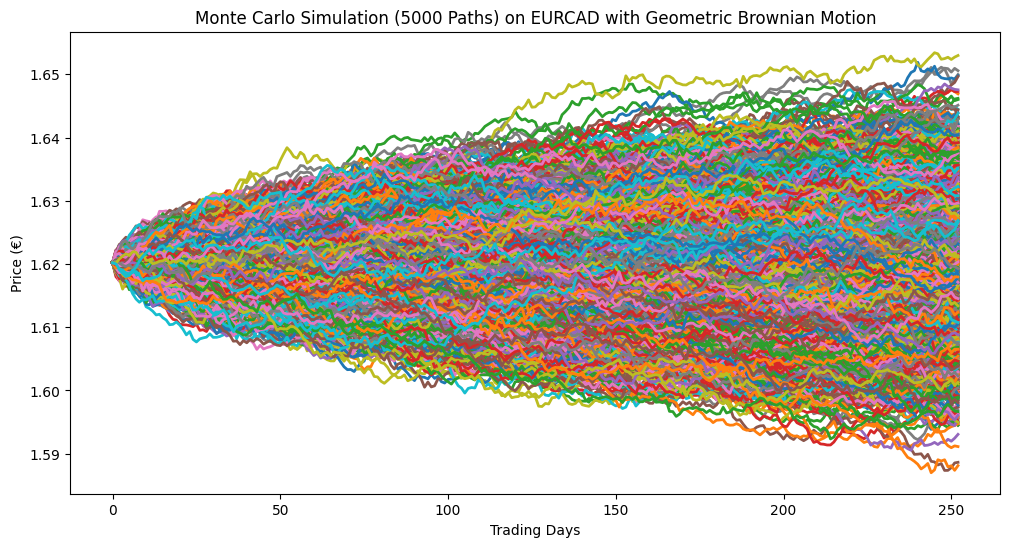

In [8]:
plt.figure(figsize=(12,6))
for path in monte_carlo:
    plt.plot(path, linewidth = 2)

plt.title("Monte Carlo Simulation (5000 Paths) on EURCAD with Geometric Brownian Motion")
plt.xlabel("Trading Days")
plt.ylabel("Price (€)")
plt.show()

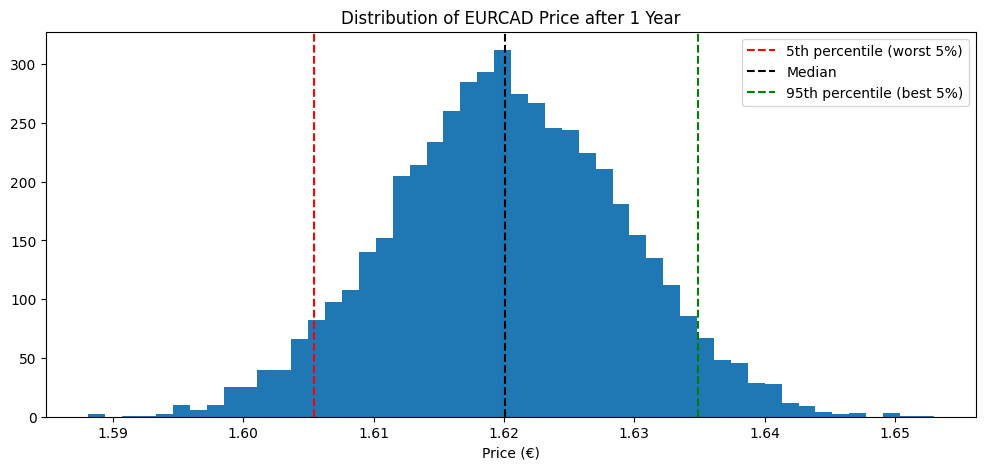

In [9]:
final_prices = [price[-1] for price in monte_carlo]

plt.figure(figsize=(12,5))
plt.hist(final_prices, bins=50)


plt.axvline(np.percentile(final_prices, 5), color="red", linestyle="--", label="5th percentile (worst 5%)")
plt.axvline(np.percentile(final_prices, 50), color="black", linestyle="--", label="Median")
plt.axvline(np.percentile(final_prices, 95), color="green", linestyle="--", label="95th percentile (best 5%)")
plt.legend()


plt.title("Distribution of EURCAD Price after 1 Year")
plt.xlabel("Price (€)")

plt.show()

In [10]:
final_prices = [path[-1] for path in monte_carlo]
final_prices = np.array(final_prices)

prob_loss = np.mean(final_prices < S0) * 100

print(f"Starting Price      : {S0:.2f} €")
print(f"Worst Case  (5%)    : {np.percentile(final_prices, 5):.2f} €")
print(f"Median      (50%)   : {np.percentile(final_prices, 50):.2f} €")
print(f"Best Case   (95%)   : {np.percentile(final_prices, 95):.2f} €")
print(f"Average Final Price : {np.mean(final_prices):.2f} €")
print(f"Probability Loss    : {prob_loss:.2f}%")

Starting Price      : 1.62 €
Worst Case  (5%)    : 1.61 €
Median      (50%)   : 1.62 €
Best Case   (95%)   : 1.63 €
Average Final Price : 1.62 €
Probability Loss    : 50.48%
